# Extremes 75th/95th-Percentile (T & P) Verification — walkthrough notebook

This notebook compares the **75th and 95th percentiles of daily temperature (T)** and **daily precipitation (P)** between observations and five model datasets, but only at **nearly-complete** land stations so that the obs and model records are like-for-like.

* **Station set:** land stations (ECCC + BCH + NOAA) with Rule-1 surviving years **>= 19 of 20** for *both* T and P (110 stations), taken from the canonical `pickles/station_tables.pkl`.
* **Model datasets (5):** `D3` = WRF d03, `D15` = WRF d02, `D75` = WRF d01, `CanRCM4`, `CanESM2`.
* **Like-for-like:** the surviving-year set is defined by the **obs** series (the 90 % annual completeness gate); each model series (complete) is restricted to the same years before the percentile is taken.
* **Percentiles:** 95th percentile of the *daily* values, pooled over all days of the shared surviving years — the same statistic the repo `extremes/` bootstrap pipeline uses (P includes dry days, the "pr as-is" convention).  The 75th percentile is added as a diagnostic for the upper half of the distribution: a model whose p95 looks good may simply have a better whole-distribution (mean-like) fit; Figure 5 (p75 bias vs p95 bias per station) separates the two.
* **Sign convention:** bias = model − observation (positive = model high).

Outputs:

| output | location |
|--------|----------|
| `extreme_p95_table.csv` / `_summary.csv` (p75 + p95) | `extremes_validation/results/` (tracked) |
| `extreme_p95.pkl`, `extreme_p95_daily.pkl` | `<BASE>/pickles/` (cache) |
| `p75_obs_vs_model.png`, `p95_obs_vs_model.png`, `p75_bias_hist.png`, `p95_bias_hist.png`, `p75_vs_p95_bias.png` | `<BASE>/figures/extremes_validation/` (git-ignored) |

This notebook is **self-contained**: it imports the shared obs-side loaders/gate from `seasonal_pooling.py` (at `BASE`) and inlines the model-file readers below.  It does **not** import `make_station_tables.py` (importing that module runs the 15-20 min root producer).


## 1. Kernel, imports & paths

Everything reads from `BASE` (the analysis working tree).  We import `seasonal_pooling as sp` for the obs daily-series builders and the Rule-1 annual gate, and use `sp._m10_file` / `sp.M10_EVAL_SLICE` for the Can* CDO per-station files.  Run single-threaded to avoid the OpenBLAS thread-spin hang noted in AGENTS.md.


In [1]:
import os
import sys
import pickle
import datetime
import warnings

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from netCDF4 import Dataset, num2date

warnings.filterwarnings('ignore', category=DeprecationWarning)
warnings.filterwarnings('ignore', category=RuntimeWarning)

# --- Paths (this workspace) ---------------------------------------------
BASE = '/gpfs/fs7/dfo/hpcmc/comda/fs2_comda/amh001/AI_WORKDIR/NOTEBOOKS'
DATA = os.path.join(BASE, 'data')          # obs loaders expect base_dir = data/
REPO_DIR = os.path.join(BASE, 'WRF-CanESM2')
RESULTS_DIR = os.path.join(REPO_DIR, 'extremes_validation', 'results')
FIG_DIR = os.path.join(BASE, 'figures', 'extremes_validation')
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

sys.path.insert(0, BASE)
import seasonal_pooling as sp

START_YEAR, END_YEAR = 1986, 2005
YEARS = tuple(range(START_YEAR, END_YEAR + 1))
MIN_YEARS_P95 = 19          # "nearly complete": >= 19 of 20 Rule-1 years
PCTLS = (75, 95)            # extreme percentiles (95 = repo convention; 75 = diagnostic)

# fonts / rcParams (Sans-Serif, 12 pt — matched to the bias figures)
plt.rcParams.update({
    'font.family': 'Sans-Serif',
    'font.size': 12,
    'axes.titlesize': 12,
    'axes.labelsize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'figure.dpi': 110,
    'savefig.dpi': 200,
    'axes.linewidth': 0.8,
})

# the five model datasets in the standard order / colours
MODELS = [
    ('D3',      'D03',     '#1f77b4', 'wrf'),   # WRF d03
    ('D15',     'D02',     '#ff7f0e', 'wrf'),   # WRF d02
    ('D75',     'D01',     '#2ca02c', 'wrf'),   # WRF d01
    ('CanRCM4', 'CanRCM4', '#9467bd', 'can'),   # CDO
    ('CanESM2', 'CanESM2', '#d62728', 'can'),   # CDO
]
VAR_UNITS = {'t': '°C', 'pr': 'mm/day'}
print('BASE      :', BASE)
print('results   :', RESULTS_DIR)
print('figures   :', FIG_DIR)
print('record    :', YEARS[0], '-', YEARS[-1])


BASE      : /gpfs/fs7/dfo/hpcmc/comda/fs2_comda/amh001/AI_WORKDIR/NOTEBOOKS
results   : /gpfs/fs7/dfo/hpcmc/comda/fs2_comda/amh001/AI_WORKDIR/NOTEBOOKS/WRF-CanESM2/extremes_validation/results
figures   : /gpfs/fs7/dfo/hpcmc/comda/fs2_comda/amh001/AI_WORKDIR/NOTEBOOKS/figures/extremes_validation
record    : 1986 - 2005


## 2. Station selection (nearly-complete records)

`pickles/station_tables.pkl` is the single canonical land table (`rule1-canonical-land-v1`).  Each per-variable `{var}_n_years` column is the number of Rule-1 surviving years for that station/variable.  We keep stations with `t_n_years >= 19` **and** `pr_n_years >= 19`.


In [2]:
with open(os.path.join(BASE, 'pickles', 'station_tables.pkl'), 'rb') as f:
    tables = pickle.load(f)
tables = {k: v for k, v in tables.items() if isinstance(v, pd.DataFrame)}
d03 = tables['D03']

sel = d03[(d03['t_n_years'] >= MIN_YEARS_P95) & (d03['pr_n_years'] >= MIN_YEARS_P95)]
ids = [str(s) for s in sel['station'].tolist()]

def agency_of(sid):
    if sid.isdigit():
        return 'ECCC'
    if sid.startswith(('USC', 'USW')):
        return 'NOAA'
    return 'BCH'

sel = sel.copy()
sel['agency'] = sel['station'].map(agency_of)
print('n selected :', len(ids))
print()
print('per-agency breakdown (selected):')
print(sel['agency'].value_counts().to_string())
print()
print('surviving-year range : t', int(sel['t_n_years'].min()), '-', int(sel['t_n_years'].max()),
      '   pr', int(sel['pr_n_years'].min()), '-', int(sel['pr_n_years'].max()))
assert len(ids) == 110, f'expected 110 nearly-complete stations, got {len(ids)}'


n selected : 110

per-agency breakdown (selected):
agency
NOAA    47
ECCC    45
BCH     18

surviving-year range : t 19 - 20    pr 19 - 20


## 3. Methods & equations

**Surviving years (Rule 1).**  For a daily obs series, a calendar year is valid only if **>= 90 %** of its expected days (leap-aware 365/366) are present; otherwise the year is NaN.  This is `sp.annual_frame(daily, kind)`; the surviving set is `annual.notna()`.  A station qualifies only if >= 19 of the 20 years survive for **both** T and P (Section 2).

**Like-for-like.**  The surviving-year set is defined by the **obs** series (the only series with gaps).  Each model series (complete) is restricted to the *same* years before the percentile is computed, so obs and model are always over an identical set of days.

**Percentile.**  For a variable `v` and the shared surviving years, gather all daily values (obs: the days that are present; model: all days of those years) and take

    p95(v) = nanpercentile( { v_d : d in shared years } , 95 )

Precipitation is pooled over **all** days of the shared years (dry days included — the "pr as-is" convention).  Temperature is the daily-mean temperature.  Bias = model p95 minus obs p95.


## 4. Daily series (obs + model), cached

We build the daily series once and cache them to `pickles/extreme_p95_daily.pkl` so re-runs are seconds.  The cache is keyed by a version tag; bump `CACHE_VERSION` if the readers or the station set change.

* **obs** — `sp.noaa_daily_series` / `sp.eccc_daily_series` / `sp.bch_daily_series` (daily T in C, daily P in mm).
* **WRF d01-d03** — `data/wrf_canon/{t,pr}_{dom}_{AGENCY}_{ID}.nc` (hourly): T = hourly `T2` - 273.15, daily mean; P = cumulative `pr` diff, clipped >= 0, daily sum.
* **CanESM2 / CanRCM4** — CDO daily files in `data/cdo_extractions/{canesm2_raw,canrcm4}_noaa113/` (T: K to C; P: kg m-2 s-1 x 86400 to mm/day).


In [3]:
CACHE_VERSION = 4
DAILY_PKL = os.path.join(BASE, 'pickles', 'extreme_p95_daily.pkl')

# ---- obs daily ----------------------------------------------------------
def obs_daily(sid, kind):
    ag = agency_of(sid)
    if ag == 'NOAA':
        return sp.noaa_daily_series(sid, kind, DATA)
    if ag == 'ECCC':
        return sp.eccc_daily_series(sid, kind, DATA)
    if ag == 'BCH':
        return sp.bch_daily_series(sid, kind, DATA)
    return None

def obs_surviving_years(daily, kind):
    # Rule-1 surviving calendar years for one obs daily series.
    if daily is None or len(daily.dropna()) == 0:
        return []
    kind_sum = 'sum' if kind == 'pr' else 'mean'
    ann = sp.annual_frame(daily, kind_sum)
    return [int(y) for y in YEARS if not np.isnan(ann.loc[y])]

# ---- WRF per-station daily (inlined; do NOT import make_station_tables) --
def wrf_station_daily(path, var_name, kind):
    nc = Dataset(path, mode='r')
    t = nc.variables['time'][:].astype(float)
    data = np.squeeze(nc.variables[var_name][:])
    nc.close()
    dates = pd.to_datetime(datetime.datetime(START_YEAR, 1, 1)) + pd.to_timedelta(t, unit='h')
    if kind in ('t', 'wind'):
        h = pd.Series(data - 273.15 if kind == 't' else data, index=dates)
        return h.groupby(h.index.normalize()).mean()
    inc = np.clip(np.diff(data), 0.0, None)
    d = pd.Series(inc, index=dates[1:].normalize())
    return d.groupby(d.index).sum()

def wrf_daily(sid, kind, dom):
    prefix = {'t': 't', 'pr': 'pr'}[kind] + '_' + dom + '_'
    d = os.path.join(BASE, 'data', 'wrf_canon')
    agmap = {'ECCC': 'ECCC_', 'NOAA': 'NOAA_', 'BCH': 'BCH_'}[agency_of(sid)]
    p = os.path.join(d, prefix + agmap + sid + '.nc')
    if not os.path.exists(p):
        return None
    return wrf_station_daily(p, {'t': 'T2', 'pr': 'pr'}[kind], kind)

# ---- Can* CDO per-station daily -----------------------------------------
def can_daily(sid, kind, model):
    model_dir = sp.M10_CanESM2_DIR if model == 'canesm2' else sp.M10_CanRCM4_DIR
    vname = {'t': 'tas', 'pr': 'pr'}[kind]
    f = sp._m10_file(DATA, model_dir, vname, sid)
    if not os.path.exists(f):
        return None
    nc = Dataset(f, mode='r')
    v = nc.variables[vname][:].astype(float).ravel()
    t = nc.variables['time'][:]
    units, cal = nc.variables['time'].units, nc.variables['time'].calendar
    nc.close()
    lo, hi = sp.M10_EVAL_SLICE[model]
    v = v[lo:hi]; t = t[lo:hi]
    dates = num2date(t, units, calendar=cal)
    idx = pd.DatetimeIndex([pd.Timestamp(int(d.year), int(d.month), int(d.day)) for d in dates])
    s = pd.Series(v, index=idx)
    if kind == 't':
        s = s - 273.15
    elif kind == 'pr':
        s = s * 86400.0
    return s

# reader dispatch keys: the tag (display name) is NOT the reader key —
# WRF needs the lowercase domain (d03/d02/d01) and Can* need the lowercase
# CDO model id ('canrcm4'/'canesm2') used to index sp.M10_EVAL_SLICE.
MODEL_KEY = {'D3': 'd03', 'D15': 'd02', 'D75': 'd01',
             'CanRCM4': 'canrcm4', 'CanESM2': 'canesm2'}

def model_daily(sid, kind, tag, kind_of):
    key = MODEL_KEY[tag]
    if kind_of == 'wrf':
        return wrf_daily(sid, kind, key)
    return can_daily(sid, kind, key)

def _restrict_years(daily, years):
    # Keep only the days that fall in the given surviving calendar years.
    if daily is None or len(daily) == 0:
        return None
    yset = set(years)
    s = daily[daily.index.year.isin(yset)]
    return s

cache = {'_version': None, 'daily': {}}
if os.path.exists(DAILY_PKL):
    with open(DAILY_PKL, 'rb') as f:
        cache = pickle.load(f)
    if cache.get('_version') != CACHE_VERSION:
        print('cache version mismatch; rebuilding')
        cache = {'_version': None, 'daily': {}}

if cache.get('_version') != CACHE_VERSION:
    cache = {'_version': None, 'daily': {}}
    n = 0
    for sid in ids:
        for kind in ('t', 'pr'):
            od = obs_daily(sid, kind)
            yrs = obs_surviving_years(od, kind)
            # store obs under a distinct key so it cannot overwrite the
            # model entries (the tag loop below reuses sid|tag|kind keys)
            cache['daily'][sid + '|_obs_|' + kind] = {'daily': od, 'years': yrs}
            for tag, _label, _c, kind_of in MODELS:
                md_ = model_daily(sid, kind, tag, kind_of)
                cache['daily'][sid + '|' + tag + '|' + kind] = _restrict_years(md_, yrs)
        n += 1
        if n % 25 == 0:
            print('  %d/%d stations' % (n, len(ids)), flush=True)
    cache['_version'] = CACHE_VERSION
    with open(DAILY_PKL, 'wb') as f:
        pickle.dump(cache, f)
    print('wrote', DAILY_PKL)
else:
    print('loaded cache', DAILY_PKL, '(version', str(CACHE_VERSION) + ')')

daily = cache['daily']
print('cached series count:', len(daily))


loaded cache /gpfs/fs7/dfo/hpcmc/comda/fs2_comda/amh001/AI_WORKDIR/NOTEBOOKS/pickles/extreme_p95_daily.pkl (version 4)
cached series count: 1320


## 5. Per-station 75th & 95th percentiles

For each station, variable and dataset we take the **75th and 95th** percentiles of the obs daily values (over its surviving years) and of the model daily values (restricted to those same years).  The 95th percentile is the repo `extremes/` convention; the 75th is a diagnostic to see whether models that look good at p95 are merely closer to the whole distribution or to its upper tail.  We store obs/model p95 and p75 and the differences, then write the per-station table and a per-dataset summary.


In [4]:
def pctl(s, p):
    if s is None:
        return np.nan
    s = s.dropna()
    if len(s) == 0:
        return np.nan
    return float(np.nanpercentile(s.values, p))

rows = []
for sid in ids:
    r_ = d03.loc[d03['station'] == sid].iloc[0]
    row = {'station': sid, 'agency': agency_of(sid),
           'lat': float(r_['lat']), 'lon': float(r_['lon']),
           'obs_elev_m': float(r_['obs_elev_m']),
           't_n_years': int(r_['t_n_years']), 'pr_n_years': int(r_['pr_n_years'])}
    for kind in ('t', 'pr'):
        oc = daily.get(sid + '|_obs_|' + kind)
        for p in PCTLS:
            op = pctl(oc['daily'], p) if oc else np.nan
            row['obs_%s_p%d' % (kind, p)] = op
            for tag, _l, _c, _k in MODELS:
                mc = daily.get(sid + '|' + tag + '|' + kind)
                mp = pctl(mc, p) if mc is not None else np.nan
                row['%s_%s_p%d' % (tag, kind, p)] = mp
                row['%s_%s_diff%d' % (tag, kind, p)] = (mp - op) if not (np.isnan(mp) or np.isnan(op)) else np.nan
    rows.append(row)

tbl = pd.DataFrame(rows).set_index('station')
with open(os.path.join(RESULTS_DIR, 'extreme_p95_table.csv'), 'w') as f:
    tbl.to_csv(f)
print('per-station table:', tbl.shape, '->', os.path.join(RESULTS_DIR, 'extreme_p95_table.csv'))

sum_rows = []
for p in PCTLS:
    for tag, label, col, _k in MODELS:
        for kind in ('t', 'pr'):
            o = tbl['obs_' + kind + '_p%d' % p]
            m = tbl[tag + '_' + kind + '_p%d' % p]
            diff = tbl[tag + '_' + kind + '_diff%d' % p]
            sum_rows.append({'dataset': tag, 'var': kind, 'pctl': p,
                             'n_obs': int(o.notna().sum()), 'n_model': int(m.notna().sum()),
                             'obs_p%d_mean' % p: float(np.nanmean(o.values)),
                             'model_p%d_mean' % p: float(np.nanmean(m.values)),
                             'diff_mean': float(np.nanmean(diff.values)),
                             'diff_median': float(np.nanmedian(diff.values))})
summ = pd.DataFrame(sum_rows)
with open(os.path.join(RESULTS_DIR, 'extreme_p95_summary.csv'), 'w') as f:
    summ.to_csv(f, index=False)
pd.set_option('display.width', 200)
print()
print('per-dataset summary (mean of per-station percentiles):')
print(summ.to_string(index=False))

with open(os.path.join(BASE, 'pickles', 'extreme_p95.pkl'), 'wb') as f:
    pickle.dump({'table': tbl, 'summary': summ, 'station_ids': ids,
                 'cache_version': CACHE_VERSION}, f)
print()
print('saved', os.path.join(BASE, 'pickles', 'extreme_p95.pkl'))


per-station table: (110, 50) -> /gpfs/fs7/dfo/hpcmc/comda/fs2_comda/amh001/AI_WORKDIR/NOTEBOOKS/WRF-CanESM2/extremes_validation/results/extreme_p95_table.csv

per-dataset summary (mean of per-station percentiles):
dataset var  pctl  n_obs  n_model  obs_p75_mean  model_p75_mean  diff_mean  diff_median  obs_p95_mean  model_p95_mean
     D3   t    75    110      110     14.633182       14.113935  -0.519247    -0.685250           NaN             NaN
     D3  pr    75    110      110      3.851229        2.645648  -1.205581    -1.066901           NaN             NaN
    D15   t    75    110      110     14.633182       13.180391  -1.452791    -1.339506           NaN             NaN
    D15  pr    75    110      110      3.851229        3.608009  -0.243220    -0.235171           NaN             NaN
    D75   t    75    110      110     14.633182       12.147113  -2.486069    -2.677111           NaN             NaN
    D75  pr    75    110      110      3.851229        4.262654   0.411425    

## 6. Figure 1 — obs vs model percentile (2 x 5 grid, rows = p75, p95)

Rows = (p75 top, p95 bottom) x variable (T left pair, P right pair); columns = the five datasets.  Each panel is a per-station scatter of **obs percentile (x)** vs **model percentile (y)** with a dashed 1:1 line; the title carries the mean bias (model - obs).


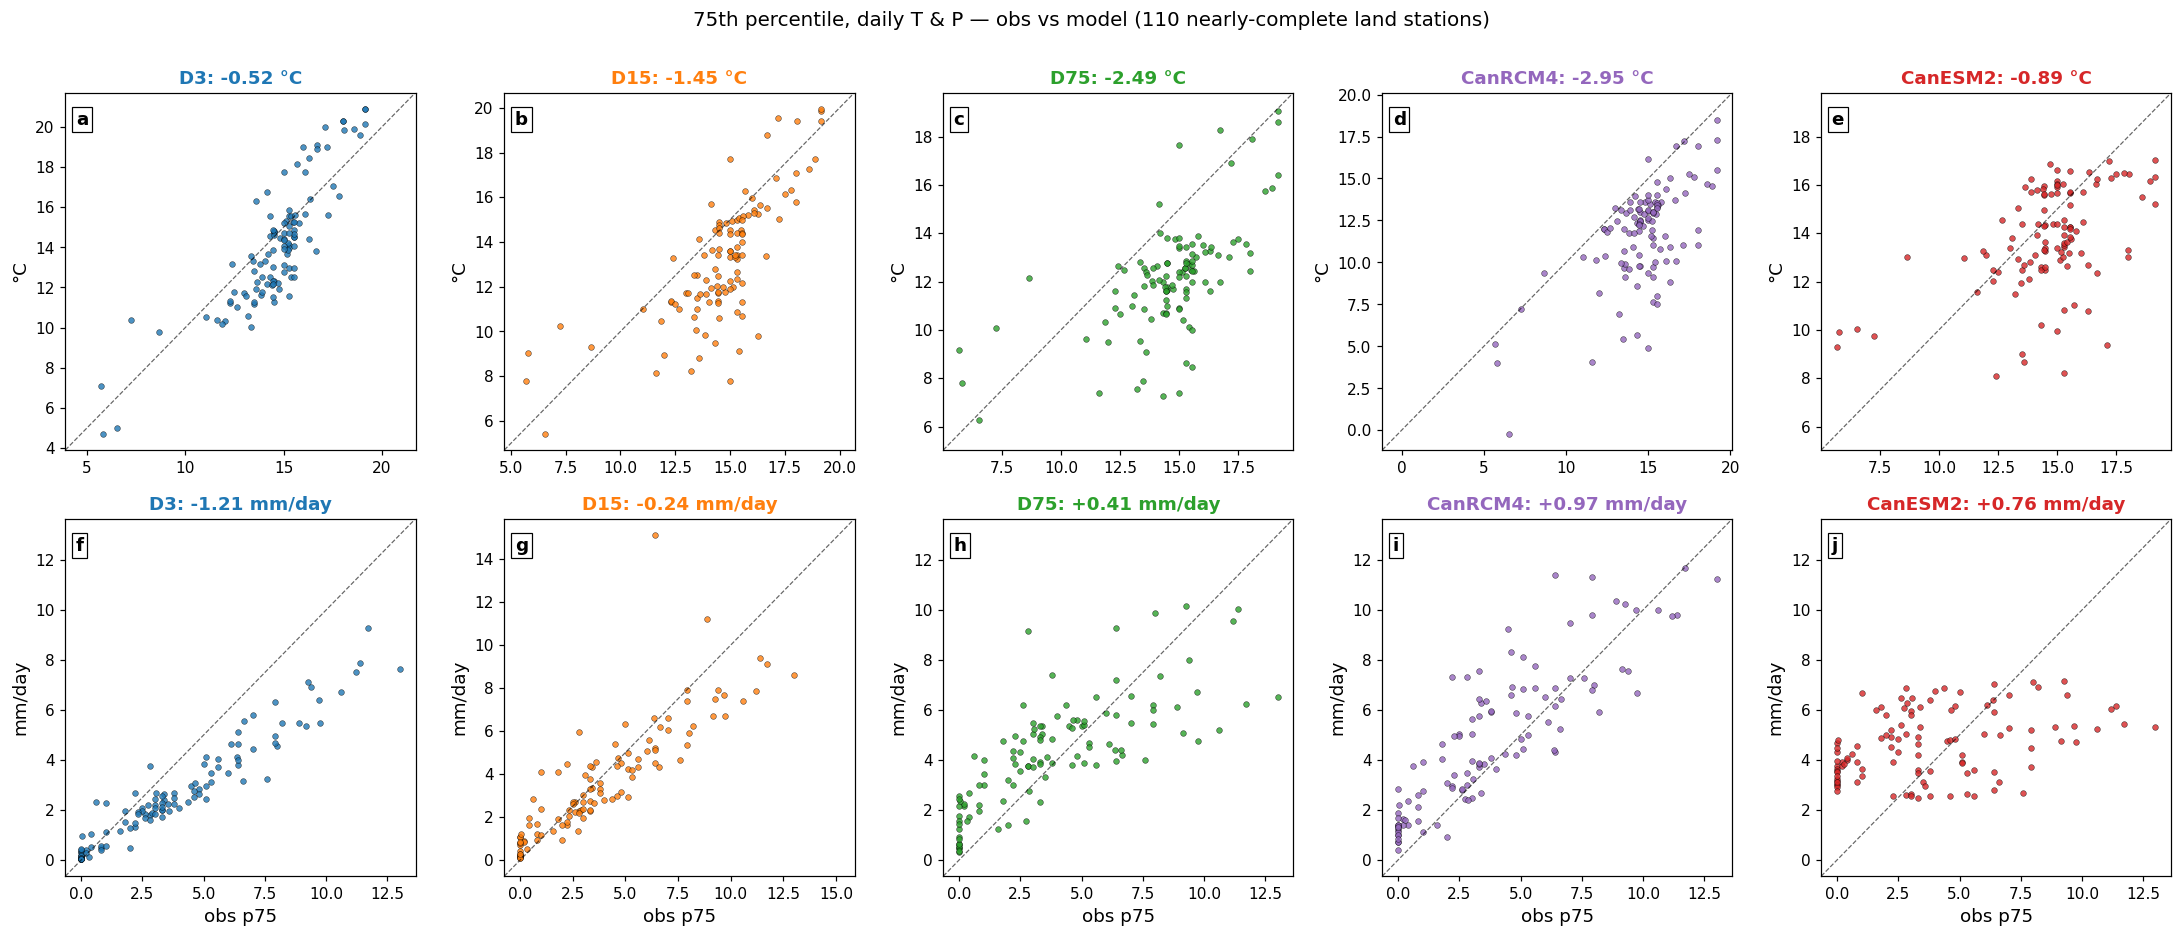

wrote /gpfs/fs7/dfo/hpcmc/comda/fs2_comda/amh001/AI_WORKDIR/NOTEBOOKS/figures/extremes_validation/p75_obs_vs_model.png


In [5]:
def pct_grid(tbl, p, fname, suptitle):
    panel_tag = 0
    def next_tag():
        nonlocal panel_tag
        tag = chr(ord('a') + panel_tag)
        panel_tag += 1
        return tag

    fig, axes = plt.subplots(2, 5, figsize=(20, 8.5))
    for r, kind in enumerate(('t', 'pr')):
        for c, (tag, label, col, _k) in enumerate(MODELS):
            ax = axes[r, c]
            o = tbl['obs_' + kind + '_p%d' % p]
            m = tbl[tag + '_' + kind + '_p%d' % p]
            ok = o.notna() & m.notna()
            ax.scatter(o[ok], m[ok], s=14, c=col, edgecolor='k', linewidth=0.3, alpha=0.8)
            lo = min(o[ok].min(), m[ok].min()); hi = max(o[ok].max(), m[ok].max())
            pad = 0.05 * (hi - lo)
            ax.plot([lo - pad, hi + pad], [lo - pad, hi + pad], 'k--', lw=0.8, alpha=0.6)
            ax.set_xlim(lo - pad, hi + pad); ax.set_ylim(lo - pad, hi + pad)
            dmean = float(np.nanmean(tbl[tag + '_' + kind + '_diff%d' % p].values))
            ax.set_title('%s: %+.2f %s' % (tag, dmean, VAR_UNITS[kind]), color=col, fontweight='bold')
            if r == 1:
                ax.set_xlabel('obs p%d' % p)
            ax.set_ylabel(VAR_UNITS[kind])
            ax.text(0.03, 0.95, next_tag(), transform=ax.transAxes, fontsize=12,
                    fontweight='bold', va='top',
                    bbox=dict(boxstyle='square,pad=0.2', fc='white', ec='black', lw=0.8))
    fig.suptitle(suptitle % len(ids), fontsize=13, y=1.00)
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, fname), bbox_inches='tight')
    plt.show()
    print('wrote', os.path.join(FIG_DIR, fname))

pct_grid(tbl, 75, 'p75_obs_vs_model.png',
         '75th percentile, daily T & P — obs vs model (%d nearly-complete land stations)')


## 7. Figure 2 — obs vs model 95th percentile (2 x 5 grid)

Same layout as Figure 1 but for the 95th percentile (the repo `extremes/` convention).


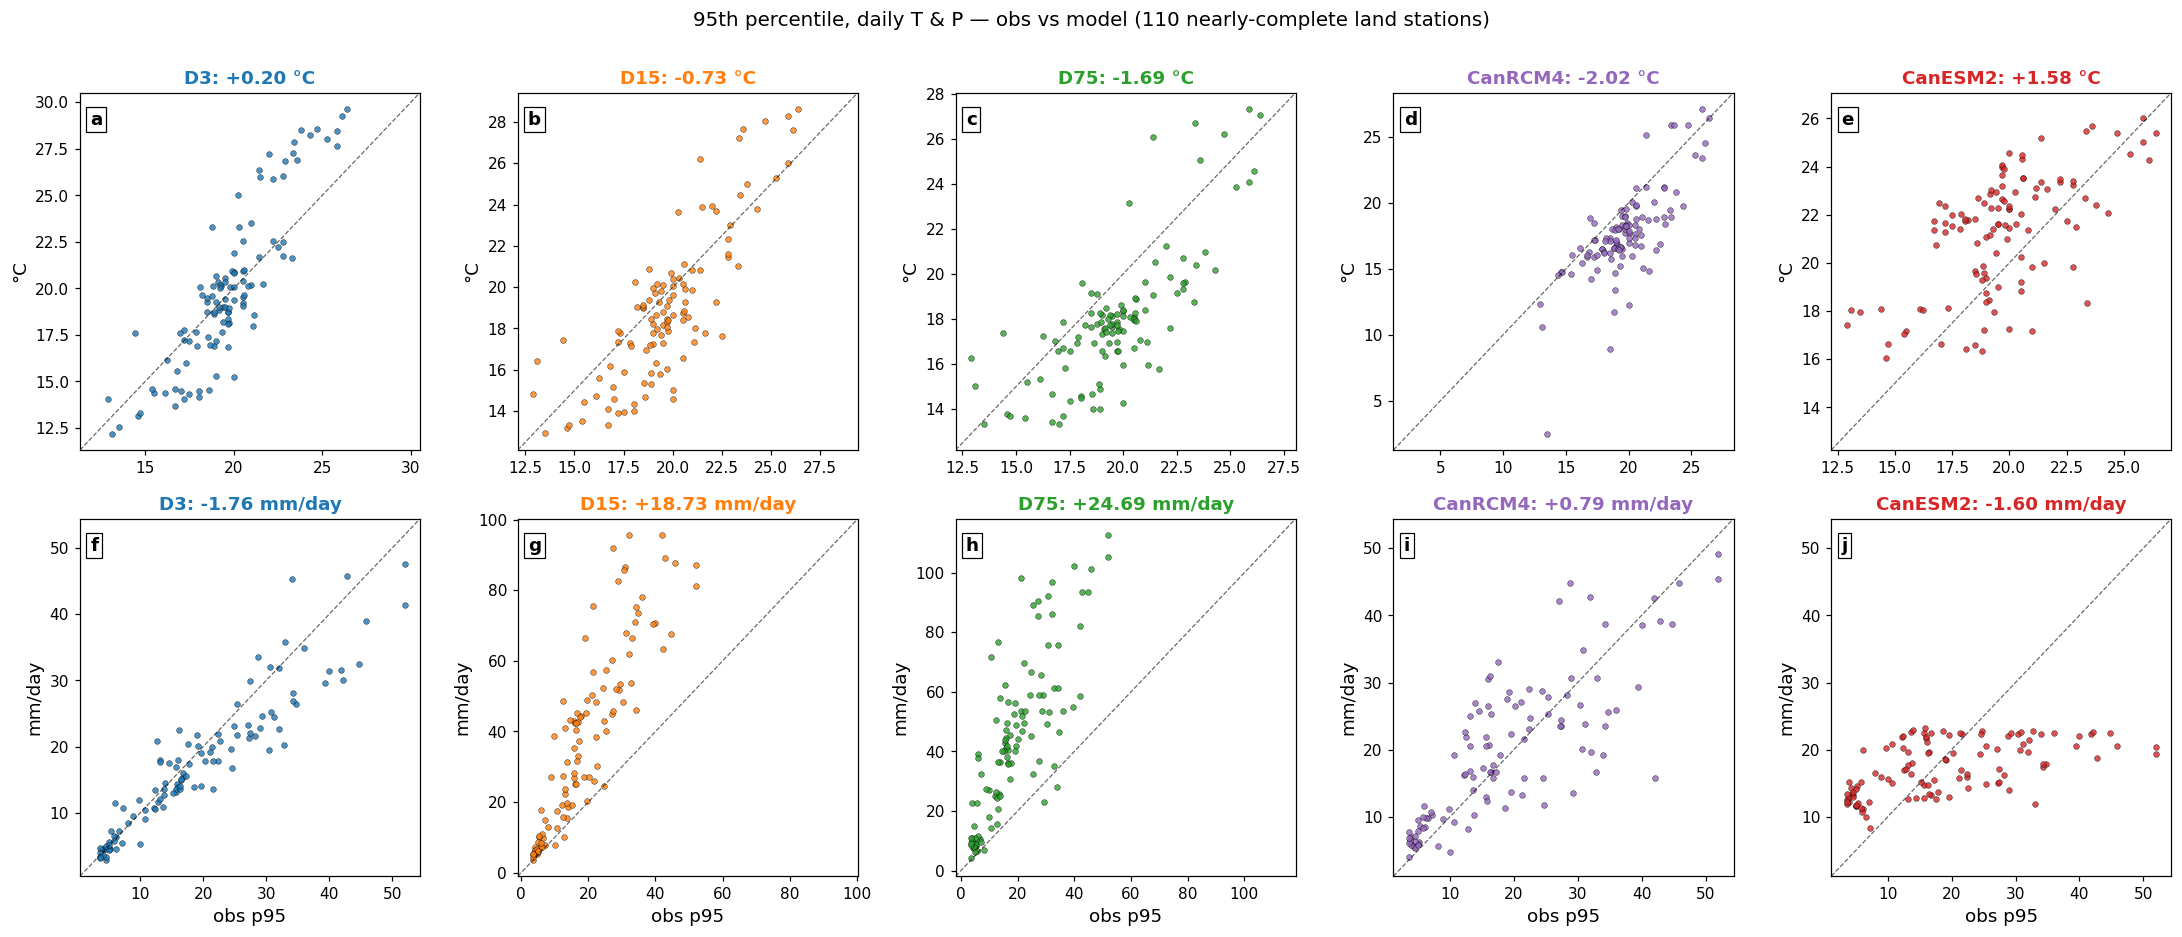

wrote /gpfs/fs7/dfo/hpcmc/comda/fs2_comda/amh001/AI_WORKDIR/NOTEBOOKS/figures/extremes_validation/p95_obs_vs_model.png


In [6]:
pct_grid(tbl, 95, 'p95_obs_vs_model.png',
         '95th percentile, daily T & P — obs vs model (%d nearly-complete land stations)')
plt.close('all')


## 8. Figures 3 & 4 — distribution of the per-station percentile bias (2 x 5 grids)

For p75 and p95 each panel is a histogram of the per-station **model - obs percentile difference** (positive = model high).


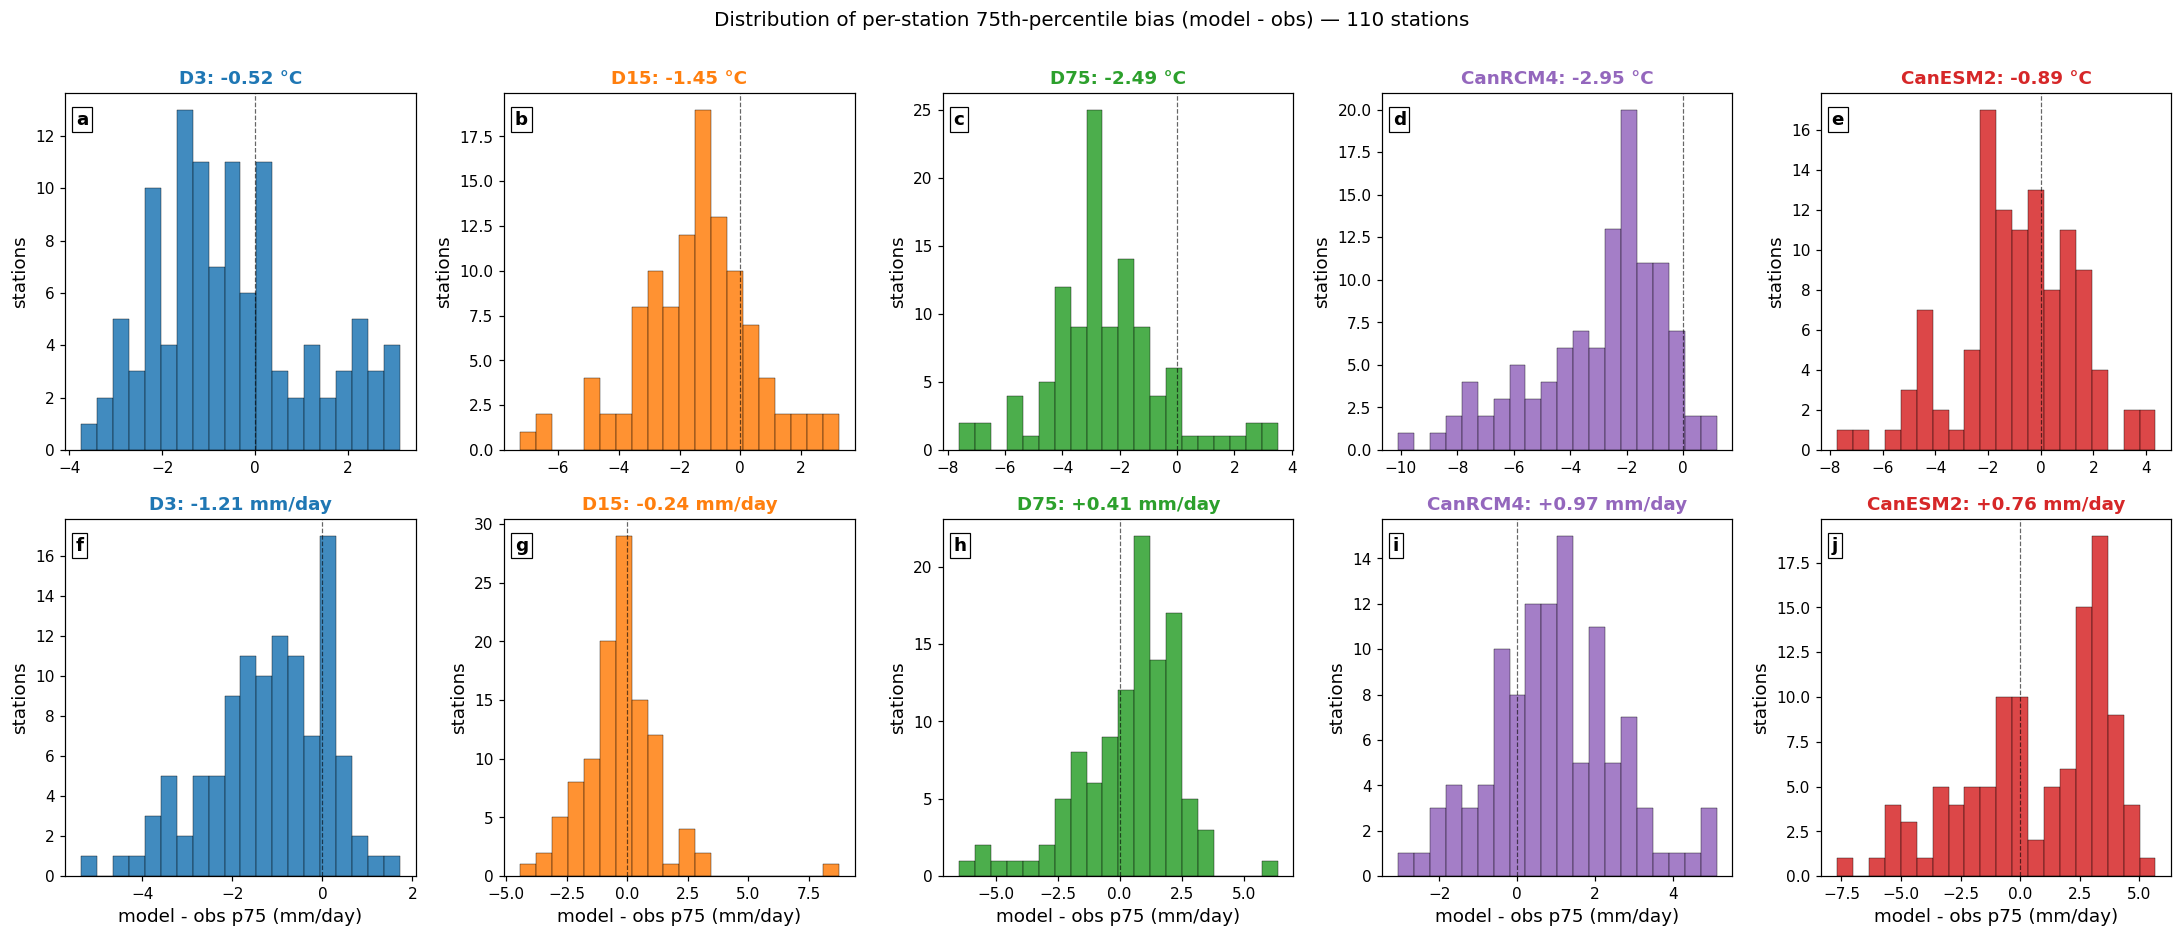

wrote /gpfs/fs7/dfo/hpcmc/comda/fs2_comda/amh001/AI_WORKDIR/NOTEBOOKS/figures/extremes_validation/p75_bias_hist.png


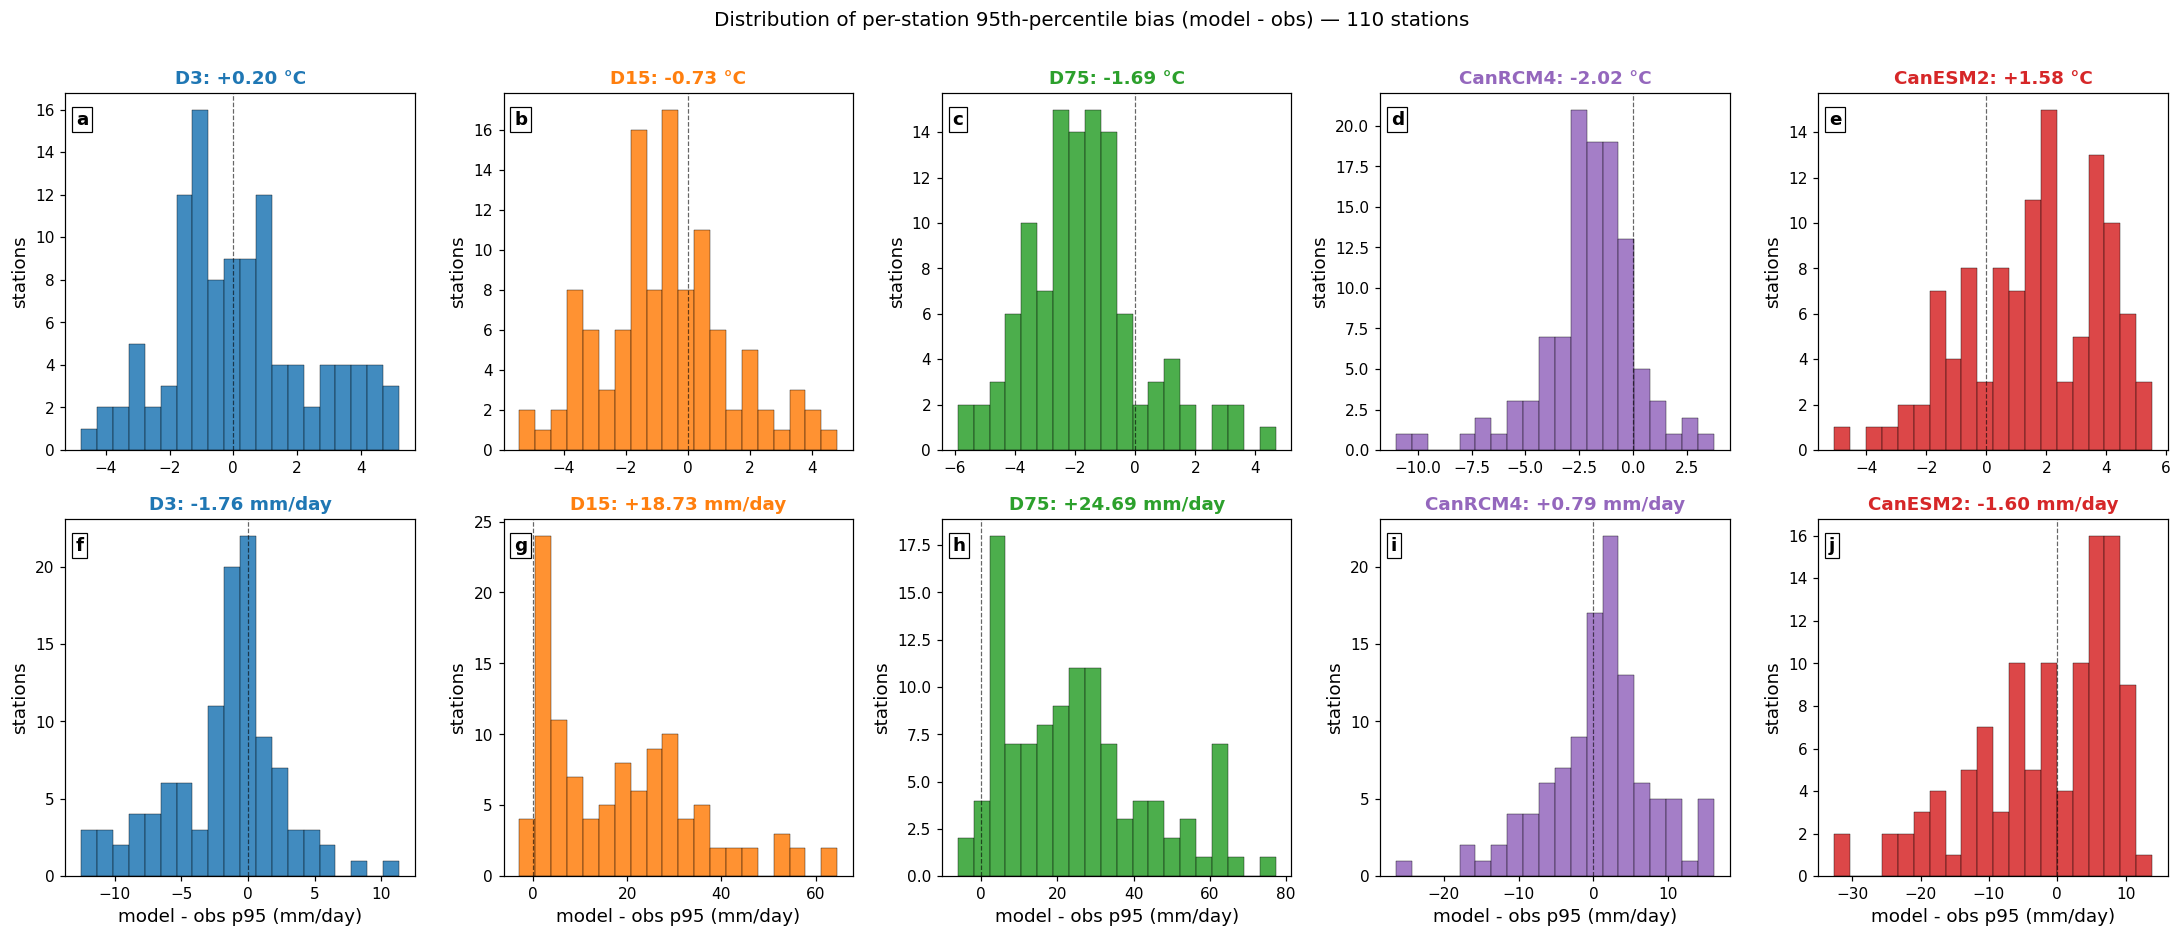

wrote /gpfs/fs7/dfo/hpcmc/comda/fs2_comda/amh001/AI_WORKDIR/NOTEBOOKS/figures/extremes_validation/p95_bias_hist.png


In [7]:
def bias_hist(tbl, p, fname, suptitle):
    panel_tag = 0
    def next_tag():
        nonlocal panel_tag
        tag = chr(ord('a') + panel_tag)
        panel_tag += 1
        return tag

    fig, axes = plt.subplots(2, 5, figsize=(20, 8.5))
    for r, kind in enumerate(('t', 'pr')):
        for c, (tag, label, col, _k) in enumerate(MODELS):
            ax = axes[r, c]
            d = tbl[tag + '_' + kind + '_diff%d' % p].dropna()
            ax.hist(d.values, bins=20, color=col, edgecolor='k', linewidth=0.3, alpha=0.85)
            ax.axvline(0.0, color='k', ls='--', lw=0.8, alpha=0.6)
            dmean = float(np.nanmean(d.values))
            ax.set_title('%s: %+.2f %s' % (tag, dmean, VAR_UNITS[kind]), color=col, fontweight='bold')
            if r == 1:
                ax.set_xlabel('model - obs p%d (' % p + VAR_UNITS[kind] + ')')
            ax.set_ylabel('stations')
            ax.text(0.03, 0.95, next_tag(), transform=ax.transAxes, fontsize=12,
                    fontweight='bold', va='top',
                    bbox=dict(boxstyle='square,pad=0.2', fc='white', ec='black', lw=0.8))
    fig.suptitle(suptitle % len(ids), fontsize=13, y=1.00)
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, fname), bbox_inches='tight')
    plt.show()
    print('wrote', os.path.join(FIG_DIR, fname))

bias_hist(tbl, 75, 'p75_bias_hist.png',
          'Distribution of per-station 75th-percentile bias (model - obs) — %d stations')
plt.close('all')
bias_hist(tbl, 95, 'p95_bias_hist.png',
          'Distribution of per-station 95th-percentile bias (model - obs) — %d stations')
plt.close('all')


## 9. Figure 5 — does 'good at p95' mean good at the upper tail? (2 x 5 grid)

Each panel is a per-station scatter of the **p75 bias (x)** vs the **p95 bias (y)** (both model - obs) for one dataset/variable.  A model that simply tracks the whole distribution better sits near the diagonal; a model whose p95 looks good because its *upper tail* happens to land near the observed one sits off it (e.g. CanESM2 for T).


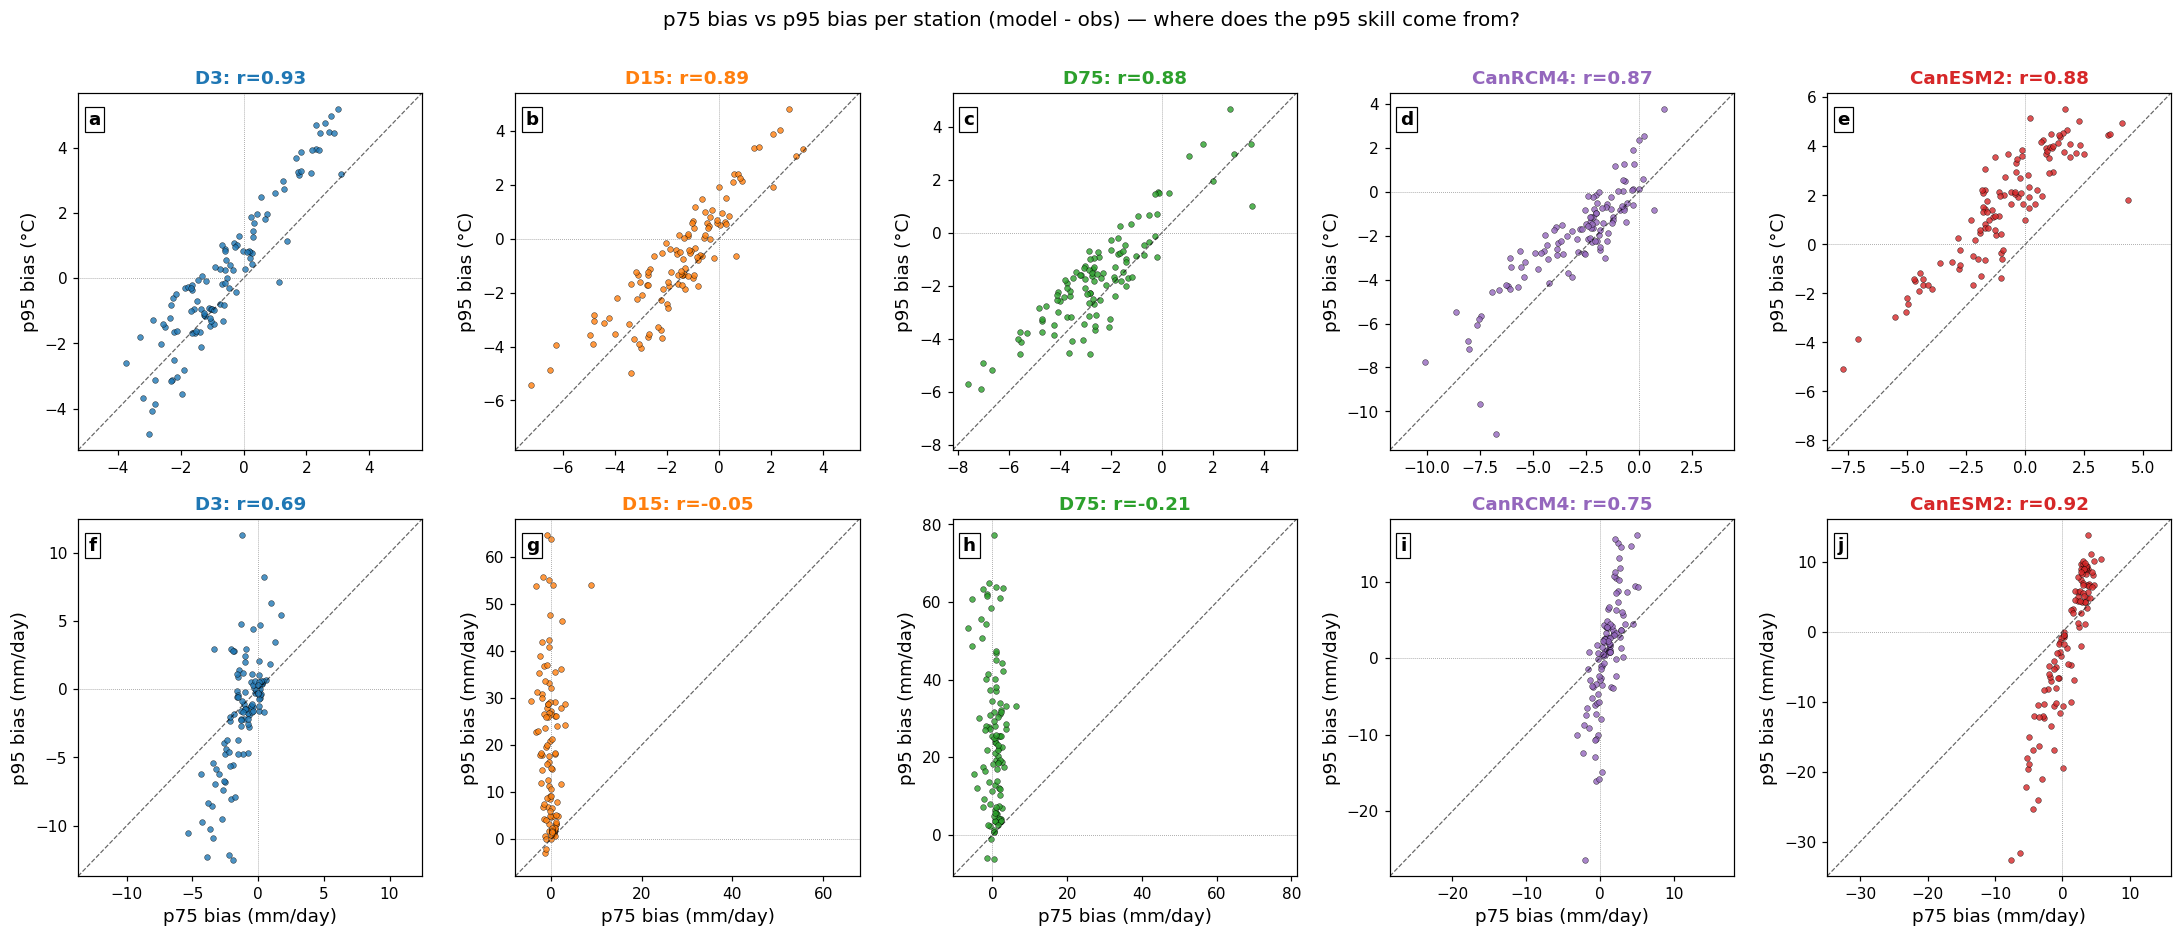

wrote /gpfs/fs7/dfo/hpcmc/comda/fs2_comda/amh001/AI_WORKDIR/NOTEBOOKS/figures/extremes_validation/p75_vs_p95_bias.png


In [8]:
panel_tag = 0
def next_tag():
    global panel_tag
    tag = chr(ord('a') + panel_tag)
    panel_tag += 1
    return tag

fig, axes = plt.subplots(2, 5, figsize=(20, 8.5))
for r, kind in enumerate(('t', 'pr')):
    for c, (tag, label, col, _k) in enumerate(MODELS):
        ax = axes[r, c]
        x = tbl[tag + '_' + kind + '_diff75'].dropna()
        y = tbl.loc[x.index, tag + '_' + kind + '_diff95'].dropna()
        ok = y.index.intersection(x.index)
        ax.scatter(x[ok], y[ok], s=14, c=col, edgecolor='k', linewidth=0.3, alpha=0.8)
        lo = min(x[ok].min(), y[ok].min()); hi = max(x[ok].max(), y[ok].max())
        pad = 0.05 * (hi - lo)
        ax.plot([lo - pad, hi + pad], [lo - pad, hi + pad], 'k--', lw=0.8, alpha=0.6)
        ax.axvline(0, color='gray', lw=0.5, ls=':'); ax.axhline(0, color='gray', lw=0.5, ls=':')
        ax.set_xlim(lo - pad, hi + pad); ax.set_ylim(lo - pad, hi + pad)
        rxy = np.corrcoef(x[ok].values, y[ok].values)[0, 1]
        ax.set_title('%s: r=%.2f' % (tag, rxy), color=col, fontweight='bold')
        if r == 1:
            ax.set_xlabel('p75 bias (' + VAR_UNITS[kind] + ')')
        ax.set_ylabel('p95 bias (' + VAR_UNITS[kind] + ')')
        ax.text(0.03, 0.95, next_tag(), transform=ax.transAxes, fontsize=12,
                fontweight='bold', va='top',
                bbox=dict(boxstyle='square,pad=0.2', fc='white', ec='black', lw=0.8))
fig.suptitle('p75 bias vs p95 bias per station (model - obs) — where does the p95 skill come from?',
             fontsize=13, y=1.00)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'p75_vs_p95_bias.png'), bbox_inches='tight')
plt.show()
print('wrote', os.path.join(FIG_DIR, 'p75_vs_p95_bias.png'))
plt.close('all')


## 10. Summary

Key numbers (mean of the per-station percentiles across the 110 nearly-complete land stations) are in `results/extreme_p95_summary.csv`; the per-station values are in `results/extreme_p95_table.csv`.

**Headline results** (mean of per-station percentile, bias = model − obs): obs p75 means T 14.63 °C / P 3.85 mm/day; obs p95 means T 19.67 °C / P 18.94 mm/day.

| dataset | T p75 bias | T p95 bias | P p75 bias | P p95 bias |
|---------|-----------|-----------|-----------|-----------|
| D3 (WRF d03)  | −0.52 °C | **+0.20 °C** | −1.21 mm/d | **−1.76 mm/d** |
| D15 (WRF d02) | −1.45 °C | −0.73 °C | −0.24 mm/d | +18.73 mm/d |
| D75 (WRF d01) | −2.49 °C | −1.69 °C | +0.41 mm/d | +24.69 mm/d |
| CanRCM4       | −2.95 °C | −2.02 °C | +0.97 mm/d | +0.79 mm/d |
| CanESM2       | −0.89 °C | +1.58 °C | +0.76 mm/d | −1.60 mm/d |

**What the 75th percentile adds.**  The p75 bias tracks the *whole-distribution* (mean-like) bias of each model — e.g. T p75 bias is −0.5 °C for D3, −3.0 °C for CanRCM4, −0.9 °C for CanESM2.  Comparing p75 to p95 (Figure 5) shows the p95 skill is **not** just a better-mean artefact:

* **T:** CanESM2's p95 bias (+1.58 °C) is *worse* than its p75 bias (−0.89 °C) — it over-heats the upper tail specifically; its p95 looks "competitive" only in absolute value, not in sign.  WRF d03 is the only dataset whose p95 bias (+0.2 °C) is smaller than its p75 bias (−0.5 °C): it reproduces the warm tail.
* **P:** D3 and CanRCM4 stay within ~2 mm/day at *both* percentiles (good across the upper half of the distribution); CanESM2 flips sign between p75 (+0.8) and p95 (−1.6) — its heavy-rain tail is too weak relative to its median rain.  The coarser WRF domains are fine at p75 (|bias| < 1 mm/day) but grossly over-state the p95 (+19 / +25 mm/day): their extreme daily rain events are far too intense.  CanRCM4's p95 pr (median per-station −8.9 %… +0.8 mm/day) is consistent with its canonical Rule-1 annual-mean P bias on the same subset (−7.8 %).

**Consistency with the repo `extremes/` convention:** the p95 here is the same statistic the `extremes/` bootstrap pipeline uses (95th percentile of *daily* values pooled over the record; P as-is, dry days included), computed like-for-like at stations rather than grid cells.

WRF d03 (D3) is the convection-permitting column and is the primary target; the coarser WRF domains and the CanESM2 / CanRCM4 rows are reference.  A positive bias means the model over-states the extreme.
